# Aula 07 — Recomendações em Escala: inferência distribuída e paralelismo

**Disciplina: Engenharia de Machine Learning — FIAP PosTech**

---

## 🎯 Objetivo da aula

Nesta aula vamos entender, na prática, por que **um único servidor vira gargalo** sob alta carga e como a **inferência distribuída** (vários servidores + balanceador de carga) escala o throughput de um sistema de ML em produção.

Usaremos como exemplo o caso de uma **plataforma de streaming de vídeos** que recomenda conteúdo em tempo real. Ao final, você será capaz de:

1. Entender o problema de latência de recomendações sob picos de tráfego.
2. Explicar de forma simples o que são **paralelismo de dados**, **paralelismo de modelos**, **batching** e **balanceamento de carga**.
3. Medir na prática a latência média e o throughput (requisições por segundo) de um sistema de inferência.
4. Comparar uma arquitetura **monolítica** (1 servidor) com um **cluster distribuído** (N servidores).
5. Avaliar se o sistema aguenta um **pico de carga** de milhares de requisições por segundo.
6. Discutir tecnologias reais (Triton, TensorFlow Serving, TorchServe, BentoML, NVIDIA Dynamo) e seus trade-offs.

## ✅ Pré-requisitos

Antes de executar este notebook, garanta o seguinte:

### 1. Software necessário

| Item | Versão mínima | Observação |
|---|---|---|
| **Python** | 3.10+ | Verifique com `python --version` |
| **Jupyter** | 1.0+ | Para abrir e executar o notebook |
| **NumPy** | 1.24+ | Geração de ruído e estatísticas |
| **Pandas** | 2.0+ | Tabela comparativa |
| **Matplotlib** | 3.7+ | Visualizações |

Este notebook é **leve e autocontido**: usa apenas `numpy`, `pandas` e `matplotlib`. **Não requer GPU**, internet ou datasets externos — roda em qualquer ambiente local simples.

### 2. Instalação das dependências

**Opção A — no terminal (recomendado):**

```bash
# a partir da pasta 07_inferencia_distribuida_paralelismo
pip install -r requirements.txt

# ou, o mínimo para este notebook:
pip install numpy pandas matplotlib jupyter
```

**Opção B — direto no notebook:** execute a célula de instalação logo abaixo (descomente a linha `%pip install ...`).

### 3. Selecionar o kernel correto

No canto superior direito do notebook, clique em **"Select Kernel"** e escolha o interpretador Python onde as dependências foram instaladas. Se aparecer `ModuleNotFoundError`, quase sempre significa que o kernel selecionado não é o mesmo ambiente da instalação — selecione o kernel certo (ou rode a célula de instalação abaixo) e execute novamente.

In [1]:
# (Opcional) Instalar as dependencias diretamente no kernel atual.
# Descomente a linha abaixo caso veja "ModuleNotFoundError" ao rodar as proximas celulas.
%pip install numpy pandas matplotlib

# Verificacao rapida do ambiente
import sys
print("Python:", sys.version.split()[0])
try:
    import numpy, pandas, matplotlib
    print("numpy:", numpy.__version__)
    print("pandas:", pandas.__version__)
    print("matplotlib:", matplotlib.__version__)
    print("Dependencias OK. Pode seguir para a proxima celula.")
except ModuleNotFoundError as e:
    print("Faltando:", e.name)
    print("=> Descomente a linha '%pip install numpy pandas matplotlib' acima e rode esta celula novamente.")

Note: you may need to restart the kernel to use updated packages.
Python: 3.13.14
numpy: 2.5.0
pandas: 3.0.3
matplotlib: 3.11.0
Dependencias OK. Pode seguir para a proxima celula.


## 1. Introdução: a plataforma de streaming de vídeos

Imagine uma **plataforma de streaming de vídeos** (pense em um "YouTube" ou "Netflix"). A cada vez que um usuário abre o app ou termina de assistir a um vídeo, um **modelo de deep learning** gera rapidamente uma nova lista de **recomendações personalizadas** (analisando o histórico do usuário, características dos vídeos, preferências de outras pessoas, etc.).

Com **poucos usuários**, um **único servidor com GPU** dava conta das recomendações.

### Características do cenário atual

| Item | Valor aproximado |
|---|---|
| Arquitetura | 1 servidor com GPU (monolítica) |
| Capacidade de 1 servidor | ~500 requisições/segundo |
| Carga em horário de pico | ~5.000 requisições/segundo |
| Latência desejada | baixa e estável (sem filas) |

### O problema

Com o crescimento para **milhões de usuários** e **picos de acesso** (horário nobre ou lançamento de uma série popular), um servidor sozinho **não dá vazão**. Em pico, chegam **milhares de requisições por segundo**; mesmo uma GPU potente chega a **100% de utilização** e começam a se formar **filas de espera**. A consequência é o **aumento da latência** das recomendações — o usuário espera mais para ver novas sugestões, prejudicando a experiência.

### O objetivo de negócio

A empresa precisa **escalar horizontalmente** a inferência: usar **vários servidores** rodando o modelo em paralelo, com um **balanceador de carga** distribuindo as requisições entre eles. Isso deve **aumentar o throughput**, **manter a latência baixa** e garantir **alta disponibilidade** mesmo sob carga extrema.

```
👥 Usuários → [balanceador de carga] → [servidor 1 | servidor 2 | ... | servidor N] → 🎬 recomendações
```

> 🧩 A pergunta central da aula é: **quantos servidores são necessários para atender ao pico de carga sem formar filas?**

## 2. Conceitos principais

Antes do hands-on, alguns conceitos simples que amarram toda a aula. A ideia é entender **como escalar** a inferência — não decorar teoria.

### 🌐 Inferência distribuída

É usar **vários servidores/dispositivos em conjunto** para atender às requisições de inferência. Serve para **aumentar o throughput** (atender mais usuários) ou para **rodar modelos gigantes** que não cabem em um só equipamento.

### 🔀 Paralelismo de dados

Coloca-se **várias cópias do mesmo modelo** rodando em paralelo (uma por servidor). As requisições são **distribuídas** entre as instâncias disponíveis. É a forma mais direta de **atender mais usuários ao mesmo tempo** — e é o foco do nosso hands-on.

### 🧩 Paralelismo de modelos

Reparte a execução de **uma única inferência** entre vários dispositivos. Útil quando o modelo é **gigante** (ex.: LLMs de 70B+ parâmetros). Pode dividir por **camadas** (pipeline) ou **dentro das camadas** (tensor), mas exige **comunicação rápida** entre dispositivos — mais complexidade.

### 📦 Batching (dinâmico)

Agrupa **várias requisições** em um único lote antes de enviar ao modelo. A GPU processa o lote de uma vez, aumentando o **throughput**. O "batching dinâmico" junta requisições que chegam quase juntas, equilibrando latência e throughput.

### ⚖️ Balanceador de carga

É o componente que **distribui cada requisição** para um servidor livre, evitando que uma máquina fique sobrecarregada enquanto outra fica ociosa. É o que faz o cluster trabalhar de forma equilibrada.

### 🖥️ Servidores de inferência

Softwares que **gerenciam modelos e recursos** de forma unificada, cuidando de batching, múltiplas instâncias e roteamento de requisições. Exemplos: **NVIDIA Triton**, **TensorFlow Serving**, **TorchServe**, **BentoML**. Simplificam o escalonamento e o monitoramento.

### 🔁 Alta disponibilidade e auto-scaling

- **Alta disponibilidade:** se um servidor falha, outro assume as requisições — o serviço não cai.
- **Auto-scaling:** o número de instâncias **cresce ou diminui automaticamente** conforme a carga, economizando recursos fora do pico.

## 3. Hands-on prático

Vamos focar em **um** conceito no hands-on: o **paralelismo de dados** com **balanceamento de carga**. Vamos **simular** um lote de requisições de usuários e medir o que acontece com **1 servidor** (monolítico) e com **N servidores** (cluster).

A ideia é simples: se cada servidor processa uma requisição em ~`t` ms, um cluster com `N` servidores atende `N` requisições **ao mesmo tempo**. O balanceador distribui as requisições igualmente, então o tempo total cai (aproximadamente) por um fator de `N`.

Primeiro, os imports e os parâmetros do nosso sistema simulado.

In [2]:
# ------------------------------------------------------------------
# IMPORTS - enxutos para manter o notebook leve e sem GPU
# ------------------------------------------------------------------
import numpy as np                # gerar tempos por requisicao e estatisticas
import pandas as pd               # montar a tabela comparativa
import matplotlib.pyplot as plt   # visualizar os resultados

# Semente fixa -> resultados reproduziveis (todos veem numeros parecidos).
np.random.seed(42)

# ------------------------------------------------------------------
# PARAMETROS DO SISTEMA DE RECOMENDACAO (numeros didaticos)
# ------------------------------------------------------------------
# Tempo que UM servidor leva para gerar as recomendacoes de UMA requisicao.
LATENCIA_POR_REQ_MS = 2.0     # ~2 ms por inferencia em 1 servidor com GPU

# Quantas requisicoes chegam no PICO (horario nobre / lancamento popular).
CARGA_PICO_RPS = 5000         # requisicoes por segundo no pico

# Capacidade de UM servidor = quantas requisicoes ele processa por segundo.
# Se cada req leva 2 ms, entao 1 servidor faz 1000/2 = 500 req/s.
CAP_1_SERVIDOR_RPS = 1000 / LATENCIA_POR_REQ_MS

print(f"Latencia por requisicao (1 servidor): {LATENCIA_POR_REQ_MS:.1f} ms")
print(f"Capacidade de 1 servidor: {CAP_1_SERVIDOR_RPS:.0f} req/s")
print(f"Carga no pico: {CARGA_PICO_RPS} req/s")

Latencia por requisicao (1 servidor): 2.0 ms
Capacidade de 1 servidor: 500 req/s
Carga no pico: 5000 req/s


In [3]:
# ==================================================================
# FUNCAO DE SIMULACAO - o coracao do experimento
# ==================================================================
# OBJETIVO: simular um cluster com N servidores atendendo a um lote de
# requisicoes de usuarios, para MEDIR latencia media, throughput (req/s)
# e se o sistema aguenta o PICO sem formar filas.
#
# POR QUE SIMULAR em vez de subir servidores de verdade?
#   - Um teste real exigiria varias maquinas com GPU, um balanceador e um
#     modelo treinado. Nesta aula o foco NAO e o modelo, e sim ENTENDER
#     como distribuir a carga aumenta o throughput. Para isso, basta
#     CONTAR quantas requisicoes cabem por segundo com N servidores.
#
# COMO O BALANCEADOR FUNCIONA (versao simplificada):
#   - O balanceador distribui as requisicoes igualmente entre os N servidores
#     (round-robin). Assim, cada servidor recebe ~ (total / N) requisicoes.
#   - Como os N servidores trabalham EM PARALELO, o tempo total e ditado
#     pelo servidor mais carregado (~ total/N requisicoes em serie).


def simular_cluster(n_servidores, n_requisicoes, latencia_ms=LATENCIA_POR_REQ_MS, jitter_ms=0.3):
    """Simula N servidores atendendo um lote de requisicoes e devolve metricas.

    Parametros
    ----------
    n_servidores  : quantas copias do modelo (servidores) rodam em paralelo.
    n_requisicoes : total de requisicoes de usuarios a atender no lote.
    latencia_ms   : tempo que UM servidor leva por requisicao (ms).
    jitter_ms     : variacao aleatoria por requisicao (realismo).

    Retorna
    -------
    dict com: n_servidores, tempo_total_s, latencia_media_ms e throughput_rps.
    """
    # 1) O balanceador distribui as requisicoes entre os servidores.
    #    Ex.: 5000 requisicoes / 10 servidores = 500 requisicoes por servidor.
    #    Usamos ceil para o servidor mais carregado (arredonda para cima).
    req_por_servidor = int(np.ceil(n_requisicoes / n_servidores))

    # 2) Sorteamos a latencia REAL de cada requisicao (em torno da media).
    #    max(0.1, ...) evita tempos negativos ou zero.
    latencias = np.maximum(0.1, latencia_ms + np.random.normal(0, jitter_ms, size=n_requisicoes))

    # 3) latencia_media_ms: tempo tipico de UMA requisicao (nao muda com N,
    #    pois cada req ainda passa por 1 servidor - o que muda e quantas
    #    rodam em paralelo).
    latencia_media = float(np.mean(latencias))

    # 4) tempo_total_s: como os servidores trabalham EM PARALELO, o lote
    #    termina quando o servidor MAIS carregado acaba a sua fila.
    #    Aprox.: (req_por_servidor) requisicoes processadas em serie.
    tempo_total_s = req_por_servidor * latencia_media / 1000.0

    # 5) throughput_rps: total de requisicoes dividido pelo tempo total.
    #    Com N servidores, o throughput cresce ~N vezes.
    throughput_rps = n_requisicoes / tempo_total_s

    return {
        "n_servidores": n_servidores,
        "tempo_total_s": tempo_total_s,
        "latencia_media_ms": latencia_media,
        "throughput_rps": throughput_rps,
    }


print("Funcao 'simular_cluster' pronta para uso.")

Funcao 'simular_cluster' pronta para uso.


### Cenário A — Arquitetura monolítica (1 servidor)

Simulamos o sistema **atual**: um único servidor tenta atender a todas as requisições do pico. Vamos processar **5.000 requisições** (1 segundo de pico) e medir quanto tempo leva e qual o throughput.

In [4]:
# Quantas requisicoes chegam em 1 segundo de pico.
N_REQ = CARGA_PICO_RPS   # 5000 requisicoes

# Cenario A - 1 servidor (monolitico)
res_mono = simular_cluster(n_servidores=1, n_requisicoes=N_REQ)

print("=== Cenario A - Monolitico (1 servidor) ===")
print(f"Servidores          : {res_mono['n_servidores']}")
print(f"Requisicoes no lote : {N_REQ}")
print(f"Tempo total         : {res_mono['tempo_total_s']:.2f} s (para 1 s de trafego)")
print(f"Latencia media/req  : {res_mono['latencia_media_ms']:.2f} ms")
print(f"Throughput          : {res_mono['throughput_rps']:.0f} req/s")

atende_mono = res_mono['throughput_rps'] >= CARGA_PICO_RPS
print(f"Atende ao pico de {CARGA_PICO_RPS} req/s? -> {'SIM' if atende_mono else 'NAO'}")

=== Cenario A - Monolitico (1 servidor) ===
Servidores          : 1
Requisicoes no lote : 5000
Tempo total         : 10.01 s (para 1 s de trafego)
Latencia media/req  : 2.00 ms
Throughput          : 500 req/s
Atende ao pico de 5000 req/s? -> NAO


Como esperado, 1 servidor (~500 req/s) leva **cerca de 10 segundos** para processar 1 segundo de tráfego de pico. Ou seja, as requisições chegam **mais rápido** do que o servidor consegue responder: **formam-se filas** e a latência efetiva do usuário dispara.

### Cenário B — Cluster distribuído (10 servidores)

Agora simulamos a **solução**: um cluster com **10 servidores** com GPU, e um balanceador de carga distribuindo as requisições entre eles. Rodamos as **mesmas 5.000 requisições** para comparar de forma justa.

In [5]:
# Cenario B - cluster com 10 servidores + balanceador de carga
N_SERVIDORES = 10
res_cluster = simular_cluster(n_servidores=N_SERVIDORES, n_requisicoes=N_REQ)

print("=== Cenario B - Cluster distribuido (10 servidores) ===")
print(f"Servidores          : {res_cluster['n_servidores']}")
print(f"Requisicoes no lote : {N_REQ}")
print(f"Tempo total         : {res_cluster['tempo_total_s']:.2f} s (para 1 s de trafego)")
print(f"Latencia media/req  : {res_cluster['latencia_media_ms']:.2f} ms")
print(f"Throughput          : {res_cluster['throughput_rps']:.0f} req/s")

atende_cluster = res_cluster['throughput_rps'] >= CARGA_PICO_RPS
print(f"Atende ao pico de {CARGA_PICO_RPS} req/s? -> {'SIM' if atende_cluster else 'NAO'}")

# Quanto o throughput aumentou com o cluster em relacao ao servidor unico?
ganho = res_cluster['throughput_rps'] / res_mono['throughput_rps']
print(f"\nO cluster escalou o throughput em ~{ganho:.0f}x em relacao ao monolitico.")

=== Cenario B - Cluster distribuido (10 servidores) ===
Servidores          : 10
Requisicoes no lote : 5000
Tempo total         : 1.00 s (para 1 s de trafego)
Latencia media/req  : 2.00 ms
Throughput          : 5007 req/s
Atende ao pico de 5000 req/s? -> SIM

O cluster escalou o throughput em ~10x em relacao ao monolitico.


## 4. Comparação dos resultados

Vamos consolidar os dois cenários em uma **tabela** e, em seguida, ver como o throughput **cresce com o número de servidores** em um **gráfico**.

In [6]:
# Tabela comparativa dos dois cenarios
def linha(res, arq):
    """Monta uma linha da tabela a partir de um resultado da simulacao."""
    return {
        "Cenario": arq,
        "Servidores": res["n_servidores"],
        "Latencia media (ms)": round(res["latencia_media_ms"], 2),
        "Throughput (req/s)": round(res["throughput_rps"]),
        "Atende ao pico?": "Sim" if res["throughput_rps"] >= CARGA_PICO_RPS else "Nao",
    }

tabela = pd.DataFrame([
    linha(res_mono, "A - Monolitico"),
    linha(res_cluster, "B - Cluster distribuido"),
])
tabela

,Cenario,Servidores,Latencia media (ms),Throughput (req/s),Atende ao pico?
0,A - Monolitico,1,2.0,500,Nao
1,B - Cluster distribuido,10,2.0,5007,Sim


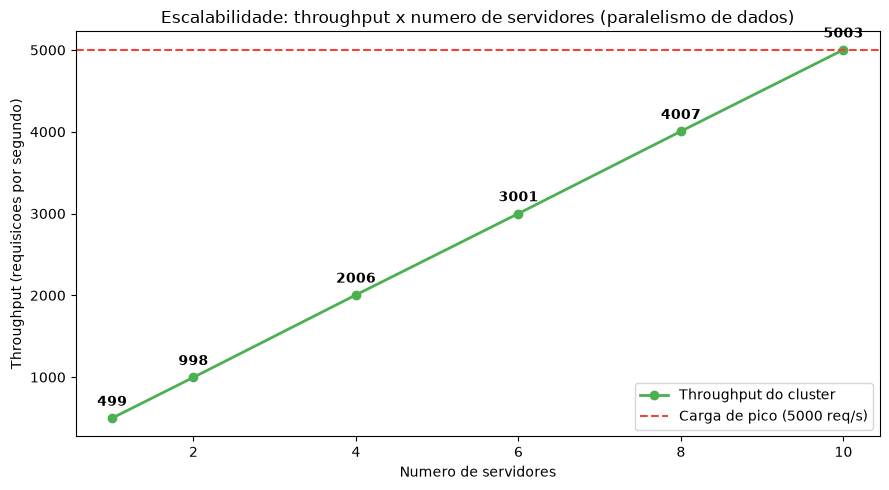

In [7]:
# Gráfico: throughput cresce (quase) linearmente com o numero de servidores.
servidores = [1, 2, 4, 6, 8, 10]
throughputs = [simular_cluster(n, N_REQ)["throughput_rps"] for n in servidores]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(servidores, throughputs, marker="o", color="#4CAF50", linewidth=2, label="Throughput do cluster")
ax.axhline(CARGA_PICO_RPS, color="#F44336", linestyle="--", label=f"Carga de pico ({CARGA_PICO_RPS} req/s)")
ax.set_xlabel("Numero de servidores")
ax.set_ylabel("Throughput (requisicoes por segundo)")
ax.set_title("Escalabilidade: throughput x numero de servidores (paralelismo de dados)")
ax.legend()
for x, y in zip(servidores, throughputs):
    ax.text(x, y + 150, f"{y:.0f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

O gráfico mostra a ideia central do **paralelismo de dados**: cada servidor adicionado soma sua capacidade ao total. A linha vermelha marca a carga de pico — o cluster passa a **atendê-la** a partir do momento em que o throughput cruza essa linha (aqui, com **10 servidores**).

## 5. Discussão técnica: como escalar de verdade?

Na simulação apenas **distribuímos as requisições** entre servidores. No mundo real, isso é feito com ferramentas e técnicas concretas. Você **não precisa implementar todas** — basta entender como cada uma ajudaria a plataforma de streaming:

| Técnica / Ferramenta | Ideia central | Como ajuda a plataforma |
|---|---|---|
| **Paralelismo de dados** | Várias cópias do modelo em paralelo | Atende mais usuários simultaneamente |
| **Paralelismo de modelos** | Uma inferência dividida entre GPUs | Suporta modelos gigantes (futuros) |
| **Balanceador de carga** | Distribui requisições entre servidores | Evita sobrecarga e filas |
| **Batching dinâmico** | Agrupa requisições em lotes | Máximo throughput por GPU |
| **NVIDIA Triton** | Servidor de inferência multi-framework | Múltiplas instâncias + batching + monitoramento |
| **TensorFlow Serving / TorchServe / BentoML** | Servir modelos em produção | Escalonamento e versionamento de modelos |
| **NVIDIA Dynamo / NeMo Megatron** | Inferência desagregada para LLMs enormes | Até ~30x mais inferências/s em modelos 70B+ |
| **Auto-scaling** | Ajusta nº de instâncias conforme a carga | Economiza recursos fora do pico |
| **Tolerância a falhas** | Outro nó assume se um servidor cai | Alta disponibilidade |

> 💡 Na prática, a plataforma usaria algo como **Triton + balanceador + auto-scaling**: em pico, sobem mais instâncias; fora do pico, o cluster encolhe para economizar. Se um nó falha, outro assume — o serviço não cai.

### ⚖️ Desafios e trade-offs

Distribuir traz ganhos enormes, mas há custos: **latência de rede** entre os nós, risco de **carga desequilibrada**, e **complexidade operacional** extra (deploy, monitoramento, orquestração). O segredo é mitigar com **monitoramento**, **auto-scaling** e **tolerância a falhas**, equilibrando **escalabilidade**, **latência** e **custo/complexidade**.

## 6. Conclusão

Respondendo às perguntas centrais da aula:

**1. Um único servidor atende à demanda de pico?**
❌ **Não.** Com capacidade de ~500 req/s, ele leva ~10 s para processar 1 s de tráfego de pico (5.000 req/s) — as requisições se acumulam e a latência dispara.

**2. O cluster distribuído resolve o gargalo?**
✅ **Sim.** Com **10 servidores** e um balanceador de carga, o throughput escala ~**10x**, atendendo às 5.000 req/s **em cerca de 1 segundo**, sem formar filas.

**3. Qual foi o impacto na latência e no throughput?**
O **throughput** subiu ~10x. A **latência por requisição** de cada usuário permaneceu praticamente a mesma de quando havia poucos usuários, porque agora, mesmo sob carga extrema, as requisições são atendidas de imediato (sem espera na fila).

**4. Por que isso importa para a experiência do usuário?**
O usuário recebe recomendações **instantâneas** mesmo no horário de pico. Além disso, a arquitetura fica **altamente disponível**: se um servidor falha, outro assume automaticamente e o serviço continua no ar.

**5. Quais trade-offs existem entre escalabilidade, complexidade e latência de rede?**
Mais servidores = mais throughput, mas também mais **custo**, **latência de rede** entre nós e **complexidade** de operação. Ferramentas de orquestração (como o Triton) e auto-scaling tornam isso viável, equilibrando desempenho e custo.

### 📌 Principais aprendizados

1. Um **único servidor** vira gargalo quando a carga cresce além da sua capacidade.
2. **Paralelismo de dados** (várias cópias do modelo) escala o throughput quase linearmente.
3. O **balanceador de carga** distribui as requisições e evita filas.
4. **Paralelismo de modelos** entra em cena para modelos gigantes que não cabem em 1 GPU.
5. Servidores de inferência (Triton, etc.) e auto-scaling tornam a escala **viável e confiável**.

### 🚀 Próximos passos sugeridos

- Variar `CARGA_PICO_RPS` e `N_SERVIDORES` e observar quantos servidores são necessários.
- Adicionar **batching** à simulação e ver o efeito no throughput por servidor.
- Explorar, em um próximo módulo, um deploy real com **NVIDIA Triton** ou **BentoML**.

---

*Material da Aula 07 — Engenharia de Machine Learning — FIAP PosTech.*